## 1. Check original Pima dataset quality

In [1]:
# Verify Pima source data and document medical zero-value issues
import pandas as pd
pima = pd.read_csv('/content/diabetes.csv')
required = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
            'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
missing_columns = [name for name in required if name not in pima.columns]
if missing_columns:
    raise ValueError(f'Missing required Pima columns: {missing_columns}')

medical_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('Pima dataset shape:', pima.shape)
print('Missing (NaN) values:\n', pima.isna().sum())
print('Duplicate rows:', pima.duplicated().sum())
print('Outcome counts:\n', pima['Outcome'].value_counts())
print('Zero counts in medical columns:\n', (pima[medical_cols] == 0).sum())
print('Rows with at least one medical zero:',
      int((pima[medical_cols] == 0).any(axis=1).sum()))

Pima dataset shape: (768, 9)
Missing (NaN) values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Duplicate rows: 0
Outcome counts:
 Outcome
0    500
1    268
Name: count, dtype: int64
Zero counts in medical columns:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Rows with at least one medical zero: 376


## 2. Generate 200 reproducible synthetic feature profiles

In [2]:
import numpy as np
import pandas as pd

# Reproducible random generation
rng = np.random.default_rng(42)

# Construct 200 hypothetical patient profiles
n = 200

synthetic_data = pd.DataFrame({
    "Pregnancies": rng.integers(0, 9, n),
    "Glucose": rng.integers(70, 201, n),
    "BloodPressure": rng.integers(55, 101, n),
    "SkinThickness": rng.integers(15, 46, n),
    "Insulin": rng.integers(30, 251, n),
    "BMI": np.round(rng.uniform(18, 46, n), 1),
    "DiabetesPedigreeFunction": np.round(
        rng.uniform(0.1, 1.5, n), 3
    ),
    "Age": rng.integers(21, 71, n)
})

# Save constructed dataset
synthetic_data.to_csv(
    "COMP8240_constructed_diabetes_dataset.csv",
    index=False
)

print("Synthetic dataset created successfully!")
print("Shape:", synthetic_data.shape)

display(synthetic_data.head(10))

print("\nDataset summary:")
display(synthetic_data.describe())

Synthetic dataset created successfully!
Shape: (200, 8)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0,117,100,34,32,38.6,0.438,23
1,6,189,90,39,96,42.8,0.551,44
2,5,134,69,37,143,43.8,0.318,43
3,3,161,99,19,232,32.1,1.324,33
4,3,129,77,40,193,32.6,0.497,27
5,7,104,78,31,202,40.4,0.886,23
6,0,170,74,25,150,26.8,1.209,21
7,6,196,61,30,54,41.4,1.197,45
8,1,104,97,44,116,31.8,0.714,25
9,0,172,55,41,250,21.2,0.767,68



Dataset summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,200.000000,200.000000,200.000000,200.000000,200.00000,200.000000,200.000000,200.000000
mean,4.100000,132.930000,77.830000,30.820000,137.22000,32.548000,0.765140,44.150000
std,2.492199,37.957992,13.986034,8.644724,65.05932,8.208758,0.417427,14.775285
min,0.000000,70.000000,55.000000,15.000000,30.00000,18.100000,0.102000,21.000000
25%,2.000000,101.000000,65.000000,24.000000,78.75000,26.175000,0.389000,31.000000
50%,4.000000,131.000000,78.000000,31.000000,142.50000,32.650000,0.750000,43.000000
75%,6.000000,166.000000,91.000000,38.000000,187.50000,39.625000,1.128750,58.000000
max,8.000000,200.000000,100.000000,45.000000,250.00000,46.000000,1.493000,70.000000


## 3. Train and evaluate XGBoost on held-out real Pima data

Zero-valued medical measurements are converted to missing values after splitting; median imputation and ADASYN are fitted on the training partition only.

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import ADASYN
from xgboost import XGBClassifier

# Pima data was loaded and checked in the preceding cell.
X = pima.drop(columns=["Outcome"])
y = pima["Outcome"]

# Split real data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Zero measurements in these columns represent missing values
missing_zero_cols = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"
]

X_train = X_train.copy()
X_test = X_test.copy()

X_train[missing_zero_cols] = X_train[missing_zero_cols].replace(0, np.nan)
X_test[missing_zero_cols] = X_test[missing_zero_cols].replace(0, np.nan)

# Imputation and ADASYN are fitted only on training data
pima_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("adasyn", ADASYN(random_state=42)),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ))
])

pima_model.fit(X_train, y_train)

# Evaluate using real, held-out Pima records
y_pred = pima_model.predict(X_test)
y_prob = pima_model.predict_proba(X_test)[:, 1]

print("=== PIMA-ONLY XGBOOST MODEL ===")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

=== PIMA-ONLY XGBOOST MODEL ===
Training records: 614
Testing records: 154

Accuracy: 0.7403
F1-score: 0.6774
ROC-AUC: 0.818

Confusion Matrix:
[[72 28]
 [12 42]]


## 4. Predict on synthetic profiles (no ground-truth labels)

=== CONSTRUCTED DATASET ANALYSIS ===
Total synthetic records: 200

Predicted class distribution:
Predicted_Class
0    106
1     94
Name: count, dtype: int64

First 10 annotated synthetic records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Predicted_Probability,Predicted_Class
0,0,117,100,34,32,38.6,0.438,23,0.290214,0
1,6,189,90,39,96,42.8,0.551,44,0.902929,1
2,5,134,69,37,143,43.8,0.318,43,0.849797,1
3,3,161,99,19,232,32.1,1.324,33,0.833259,1
4,3,129,77,40,193,32.6,0.497,27,0.662087,1
5,7,104,78,31,202,40.4,0.886,23,0.501836,1
6,0,170,74,25,150,26.8,1.209,21,0.302778,0
7,6,196,61,30,54,41.4,1.197,45,0.700593,1
8,1,104,97,44,116,31.8,0.714,25,0.300418,0
9,0,172,55,41,250,21.2,0.767,68,0.178784,0


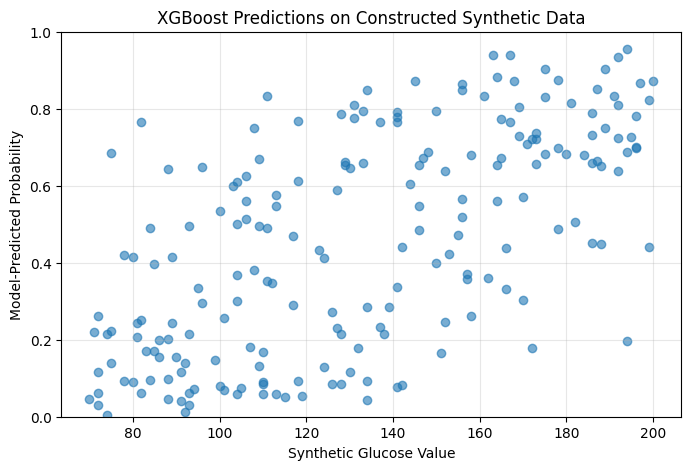


SUCCESS: Synthetic predictions completed!
Annotated dataset saved successfully!


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the 200 profiles generated above; no separate upload required
synthetic = synthetic_data.copy()

# Select ONLY the 8 features used during model training
X_synthetic = synthetic[X_train.columns].copy()

# Generate predictions using the original 8 features
predicted_probabilities = pima_model.predict_proba(
    X_synthetic
)[:, 1]

predicted_classes = pima_model.predict(
    X_synthetic
)

# Add predictions AFTER model evaluation
synthetic["Predicted_Probability"] = predicted_probabilities
synthetic["Predicted_Class"] = predicted_classes

print("=== CONSTRUCTED DATASET ANALYSIS ===")
print("Total synthetic records:", len(synthetic))

print("\nPredicted class distribution:")
print(synthetic["Predicted_Class"].value_counts())

print("\nFirst 10 annotated synthetic records:")
display(synthetic.head(10))

# Visualise model predictions
plt.figure(figsize=(8, 5))

plt.scatter(
    synthetic["Glucose"],
    synthetic["Predicted_Probability"],
    alpha=0.6
)

plt.xlabel("Synthetic Glucose Value")
plt.ylabel("Model-Predicted Probability")
plt.title("XGBoost Predictions on Constructed Synthetic Data")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

# Save annotated dataset
synthetic.to_csv(
    "COMP8240_synthetic_with_predictions.csv",
    index=False
)

print("\nSUCCESS: Synthetic predictions completed!")
print("Annotated dataset saved successfully!")

## 5. Controlled feature perturbations

Only one feature changes at a time. These are **model sensitivity illustrations**, not causal or medical claims.

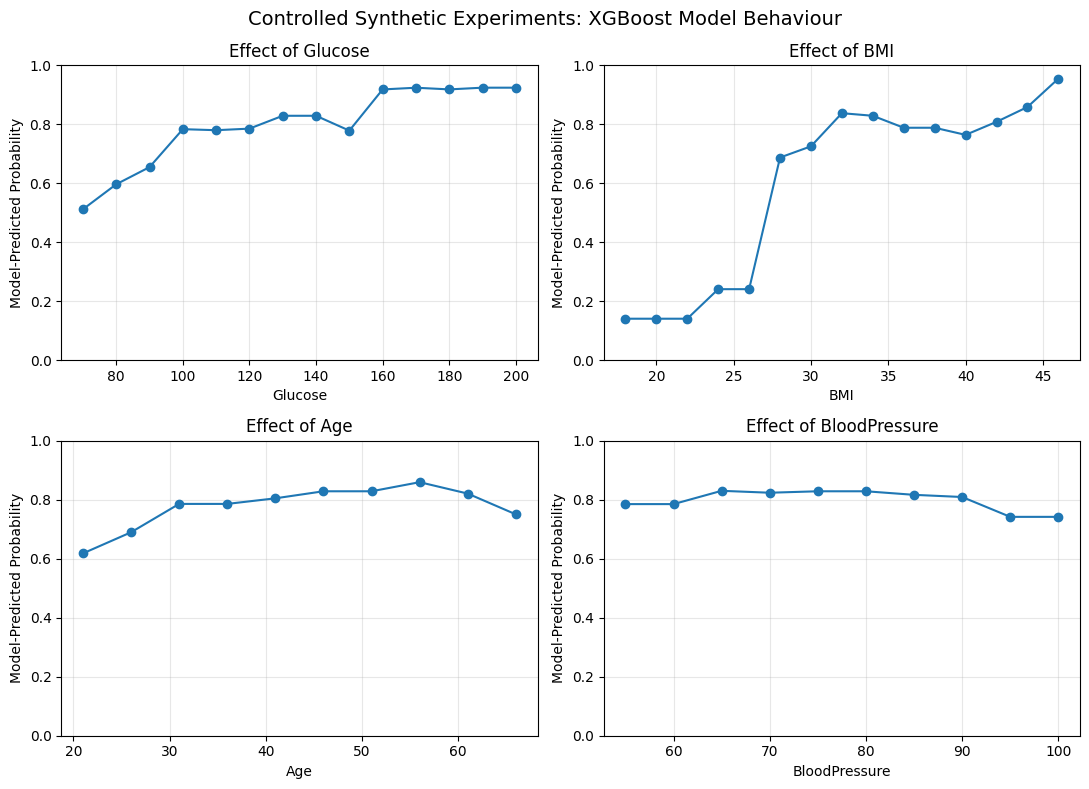

Controlled experiments completed!
Total scenarios tested: 49


,Changed_Feature,Feature_Value,Predicted_Probability
0,Glucose,70,0.511751
1,Glucose,80,0.596675
2,Glucose,90,0.654833
3,Glucose,100,0.783502
4,Glucose,110,0.780045
5,Glucose,120,0.785346
6,Glucose,130,0.828949
7,Glucose,140,0.828949
8,Glucose,150,0.778581
9,Glucose,160,0.918264


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use one representative synthetic profile
baseline = synthetic[X_train.columns].median().to_frame().T

# Features and hypothetical values to test
experiments = {
    "Glucose": np.arange(70, 201, 10),
    "BMI": np.arange(18, 47, 2),
    "Age": np.arange(21, 71, 5),
    "BloodPressure": np.arange(55, 101, 5)
}

results = []

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (feature, values) in zip(axes.flat, experiments.items()):

    # Hold every other feature constant
    scenarios = pd.concat(
        [baseline] * len(values),
        ignore_index=True
    )

    scenarios[feature] = values

    probabilities = pima_model.predict_proba(
        scenarios[X_train.columns]
    )[:, 1]

    for value, probability in zip(values, probabilities):
        results.append({
            "Changed_Feature": feature,
            "Feature_Value": value,
            "Predicted_Probability": probability
        })

    ax.plot(values, probabilities, marker="o")
    ax.set_title(f"Effect of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Model-Predicted Probability")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

plt.suptitle(
    "Controlled Synthetic Experiments: XGBoost Model Behaviour",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Save the controlled experiment results
controlled_results = pd.DataFrame(results)

controlled_results.to_csv(
    "COMP8240_controlled_experiment_results.csv",
    index=False
)

print("Controlled experiments completed!")
print("Total scenarios tested:", len(controlled_results))

display(controlled_results.head(10))

## Reporting notes

The previous notebook saved a Pima held-out ROC-AUC of **0.8180** and **106 class-0 / 94 class-1** synthetic predictions; rerun to obtain fresh results. The model's real-Pima test scores measure classification performance on held-out real data. No accuracy, F1-score or ROC-AUC can be calculated for the 200 unlabelled synthetic profiles. The generated CSV and annotated predictions are separate artifacts.